# Projeto 2 - C11: Análise e Previsão de Séries Temporais
**Instituto Nacional de Telecomunicações (Inatel)**  
**Docente:** Prof. Dr. Renzo Mesquita Paranaíba  
**Integrantes:** Igor Araujo (479 - GES) | Kevin Lopes do Vale (1955 - GEC) | Felipe Fróes Pereira (566 - GES)

---

## Objetivo do Notebook
Analisar e prever a série temporal de consumo elétrico **`PJME_hourly.csv`** (*PJM East Hourly Energy Consumption*), reamostrada para **média semanal (`resample('W').mean()`)**, seguindo estritamente as etapas da disciplina:
1. **Carregamento e limpeza do timestamp** (conversão para `datetime`, ordenação cronológica, remoção de duplicatas e reamostragem semanal).
2. **Gráfico 1:** Visualização da série temporal original em português.
3. **Gráfico 2:** Decomposição aditiva da série (`seasonal_decompose` com `model='additive'` e `period=52`).
4. **Gráfico 3:** Previsão de 52 semanas com **Suavização Exponencial de Holt-Winters** (`ExponentialSmoothing` com `trend='add'`, `seasonal='add'`, `seasonal_periods=52`) e avaliação exclusiva pelo **MAPE**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Padronização visual dos gráficos para os slides da apresentação (5 minutos)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#CBD5E1",
    "axes.grid": True,
    "grid.color": "#E2E8F0",
    "grid.linestyle": "--",
    "grid.alpha": 0.8,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "legend.fontsize": 10,
})

## 1. Carregamento e Limpeza do Timestamp
O dataset bruto `PJME_hourly.csv` possui registros horários de 2002 a 2018 fora de ordem cronológica e com 4 timestamps duplicados (decorrentes de mudanças de horário de verão). Realizamos a conversão para `datetime`, ordenação cronológica, remoção de duplicatas e reamostragem para a **média semanal (`resample('W').mean()`)**.

In [2]:
# Localização automática do arquivo na pasta c11-2-data
caminho_csv = Path("../c11-2-data/PJME_hourly.csv")
if not caminho_csv.exists():
    caminho_csv = Path("c11-2-data/PJME_hourly.csv")

df = pd.read_csv(caminho_csv)

# Limpeza e padronização do timestamp
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime")
df = df.drop_duplicates(subset=["Datetime"], keep="first")
df = df.set_index("Datetime")

# Reamostragem para média semanal
serie_semanal = df["PJME_MW"].resample("W").mean().dropna()
serie_semanal.name = "Consumo_Semanal_MW"

print(f"Período analisado: {serie_semanal.index.min().strftime('%d/%m/%Y')} a {serie_semanal.index.max().strftime('%d/%m/%Y')}")
print(f"Total de semanas (após resample 'W'): {len(serie_semanal)} semanas")
print(f"Consumo médio histórico: {serie_semanal.mean():.2f} MW")

Período analisado: 06/01/2002 a 05/08/2018
Total de semanas (após resample 'W'): 866 semanas
Consumo médio histórico: 32082.36 MW


## 2. Gráfico 1: Série Temporal Original
Traçamos a série temporal do consumo médio semanal de energia elétrica na região PJM East entre 2002 e 2018, destacando a média histórica.

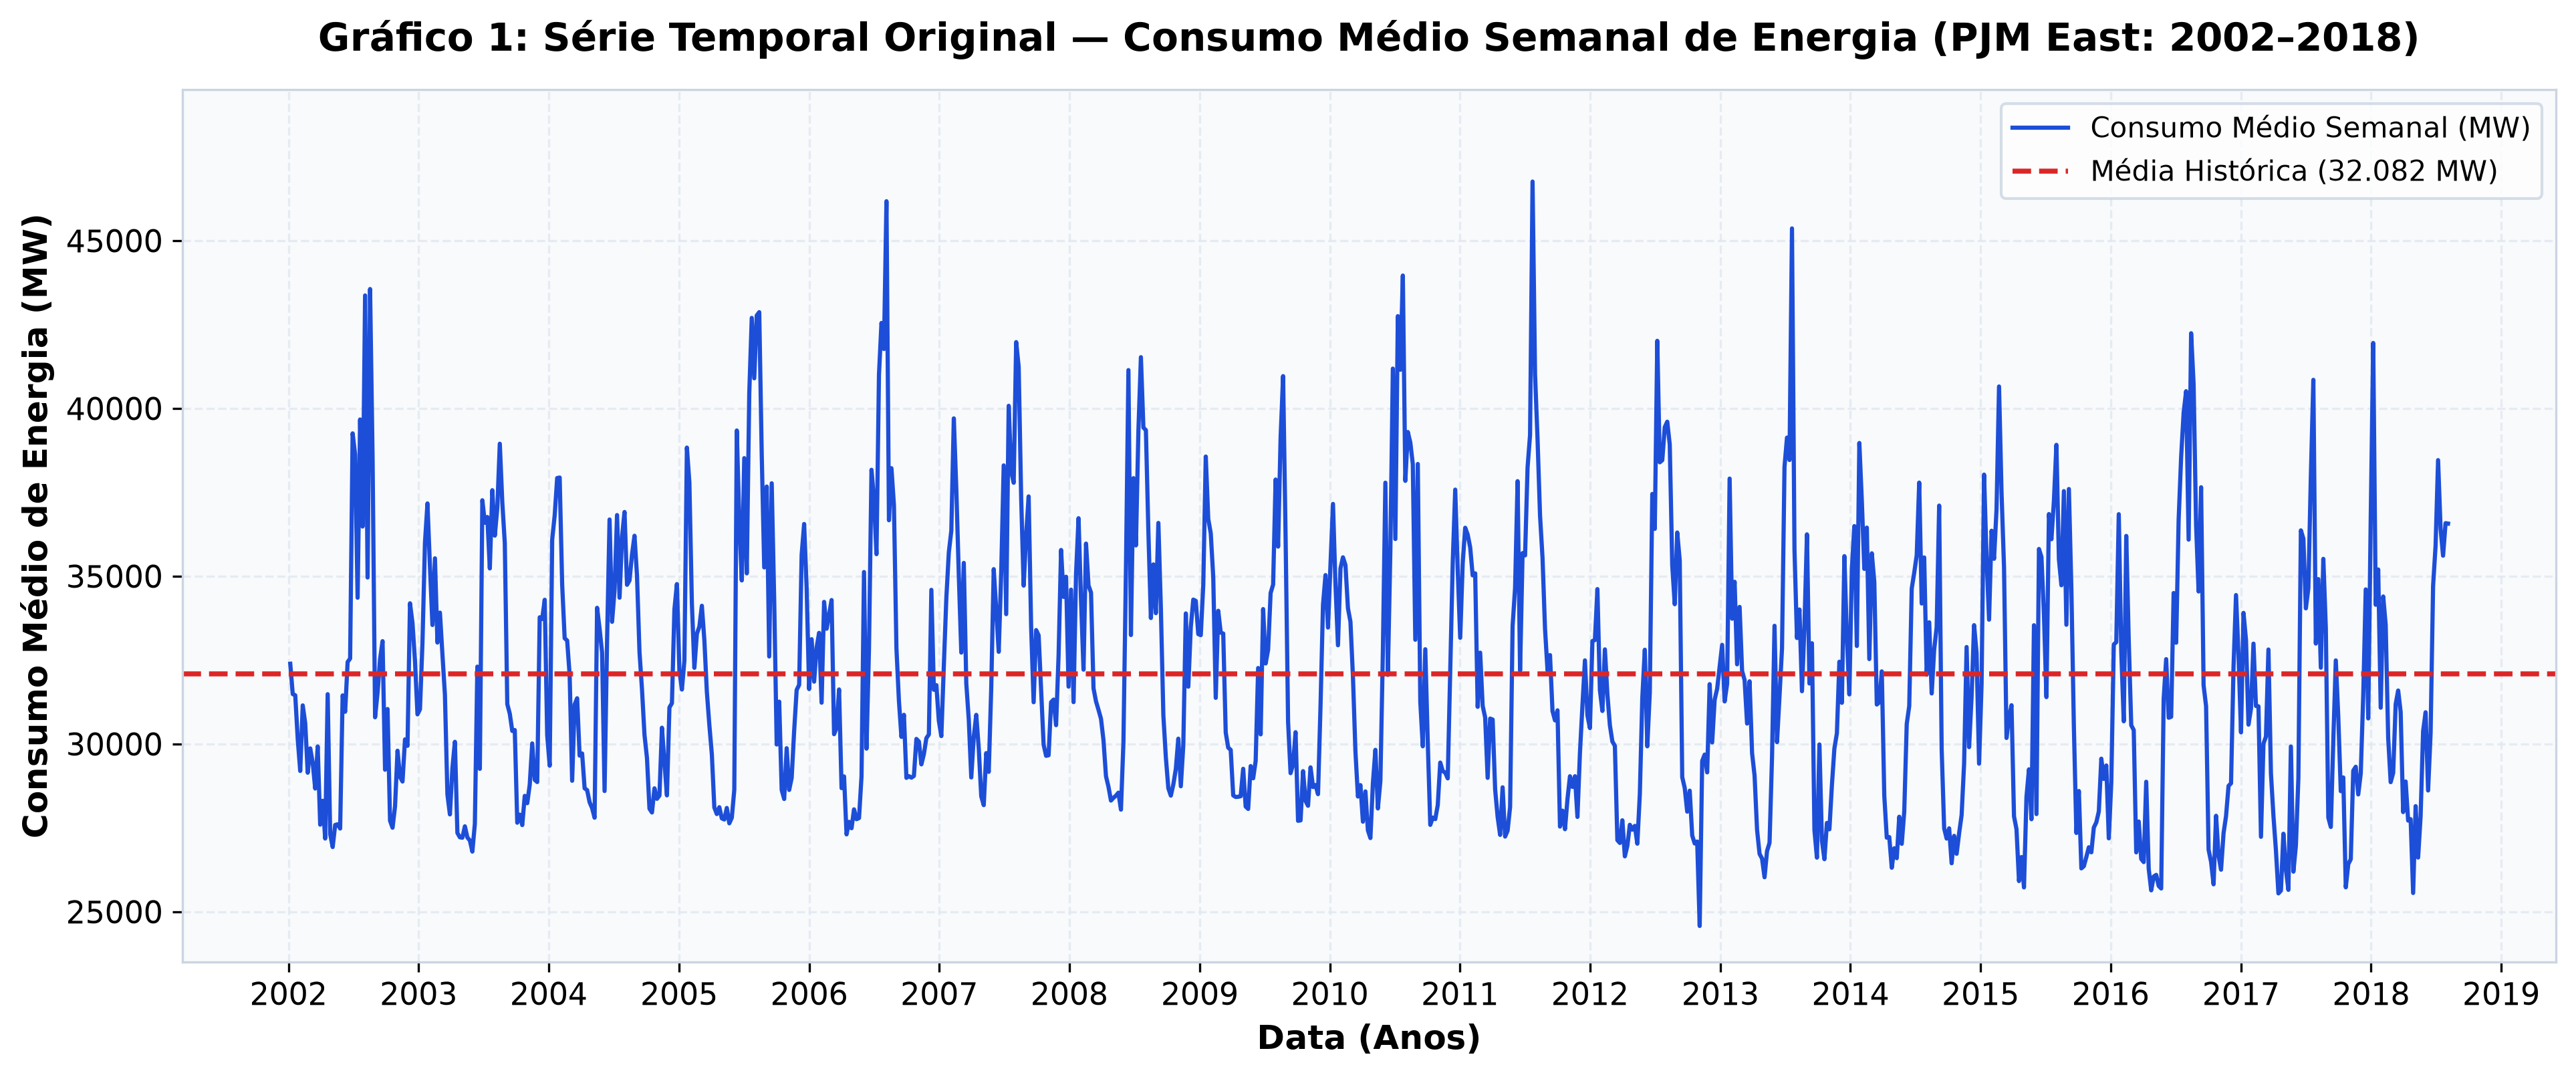

In [3]:
fig, ax = plt.subplots(figsize=(13, 5.5))
media_historica = serie_semanal.mean()

ax.plot(
    serie_semanal.index,
    serie_semanal.values,
    color="#1D4ED8",
    linewidth=1.5,
    label="Consumo Médio Semanal (MW)",
)
ax.axhline(
    media_historica,
    color="#DC2626",
    linestyle="--",
    linewidth=1.8,
    label=f"Média Histórica ({media_historica:,.0f} MW)".replace(",", "."),
)

ax.set_title("Gráfico 1: Série Temporal Original — Consumo Médio Semanal de Energia (PJM East: 2002–2018)", pad=14)
ax.set_xlabel("Data (Anos)")
ax.set_ylabel("Consumo Médio de Energia (MW)")
ax.set_ylim(23500, 49500)
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 3. Gráfico 2: Decomposição da Série Temporal
Aplicamos `seasonal_decompose` com **`model='additive'`** e **`period=52`** (52 semanas = 1 ciclo anual), separando a série em **Observada**, **Tendência**, **Sazonalidade** e **Resíduo**.

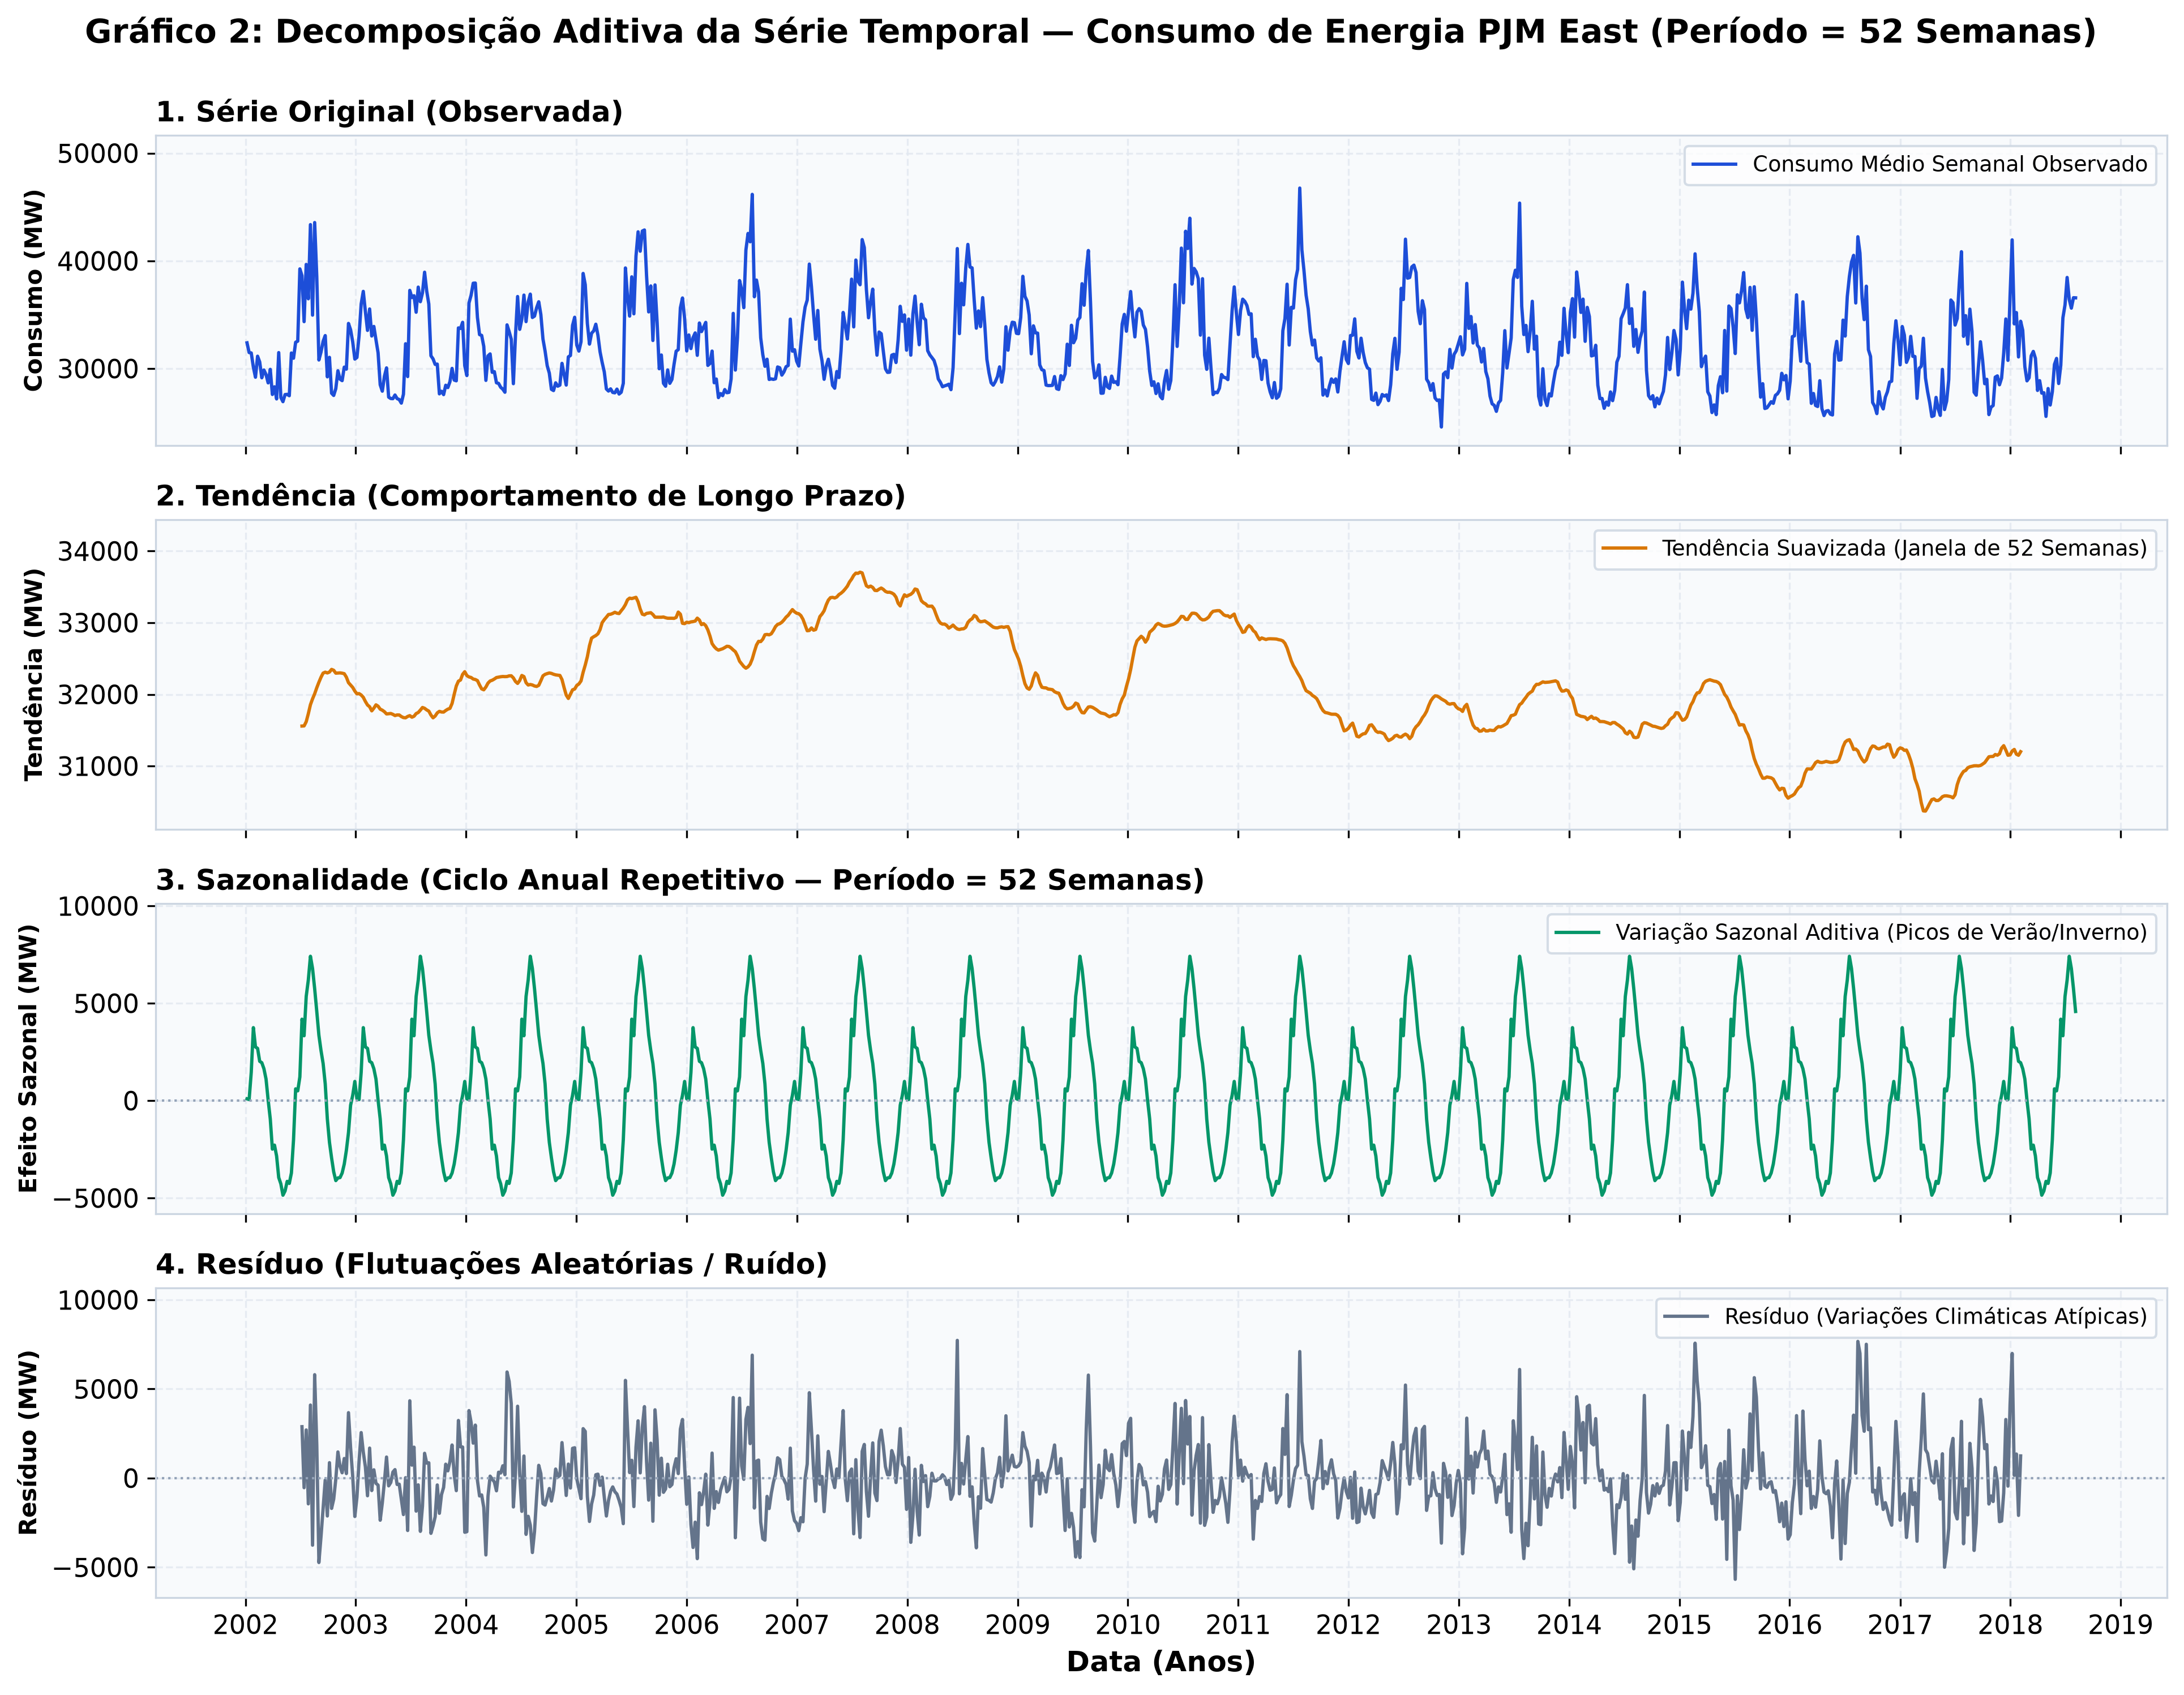

In [4]:
decomposicao = seasonal_decompose(serie_semanal, model="additive", period=52)

fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
componentes = [
    (decomposicao.observed, "1. Série Original (Observada)", "Consumo (MW)", "#1D4ED8", "Consumo Médio Semanal Observado"),
    (decomposicao.trend, "2. Tendência (Comportamento de Longo Prazo)", "Tendência (MW)", "#D97706", "Tendência Suavizada (Janela de 52 Semanas)"),
    (decomposicao.seasonal, "3. Sazonalidade (Ciclo Anual Repetitivo — Período = 52 Semanas)", "Efeito Sazonal (MW)", "#059669", "Variação Sazonal Aditiva (Picos de Verão/Inverno)"),
    (decomposicao.resid, "4. Resíduo (Flutuações Aleatórias / Ruído)", "Resíduo (MW)", "#64748B", "Resíduo (Variações Climáticas Atípicas)"),
]

for ax, (dados, titulo, ylabel, cor, legenda) in zip(axes, componentes):
    ax.plot(dados.index, dados.values, color=cor, linewidth=1.4, label=legenda)
    if titulo.startswith("3.") or titulo.startswith("4."):
        ax.axhline(0, color="#94A3B8", linestyle=":", linewidth=1.0)
    d_min, d_max = float(dados.min()), float(dados.max())
    margem = (d_max - d_min) * 0.22
    ax.set_ylim(d_min - margem * 0.35, d_max + margem)
    ax.set_title(titulo, fontsize=12, loc="left", pad=6)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Data (Anos)")
axes[-1].xaxis.set_major_locator(mdates.YearLocator(1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle(
    "Gráfico 2: Decomposição Aditiva da Série Temporal — Consumo de Energia PJM East (Período = 52 Semanas)",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
plt.tight_layout()
plt.show()

## 4. Gráfico 3: Previsão de 52 Semanas (Holt-Winters) e Cálculo do MAPE
Utilizamos a **Suavização Exponencial Tripla de Holt-Winters** (`ExponentialSmoothing` com `trend='add'`, `seasonal='add'` e `seasonal_periods=52`) para prever **52 semanas** (1 ano completo) e avaliamos a qualidade da previsão exclusivamente por meio do **MAPE (Erro Percentual Absoluto Médio)**.

MAPE da previsão de 52 semanas (Holt-Winters Aditivo): 7.35%


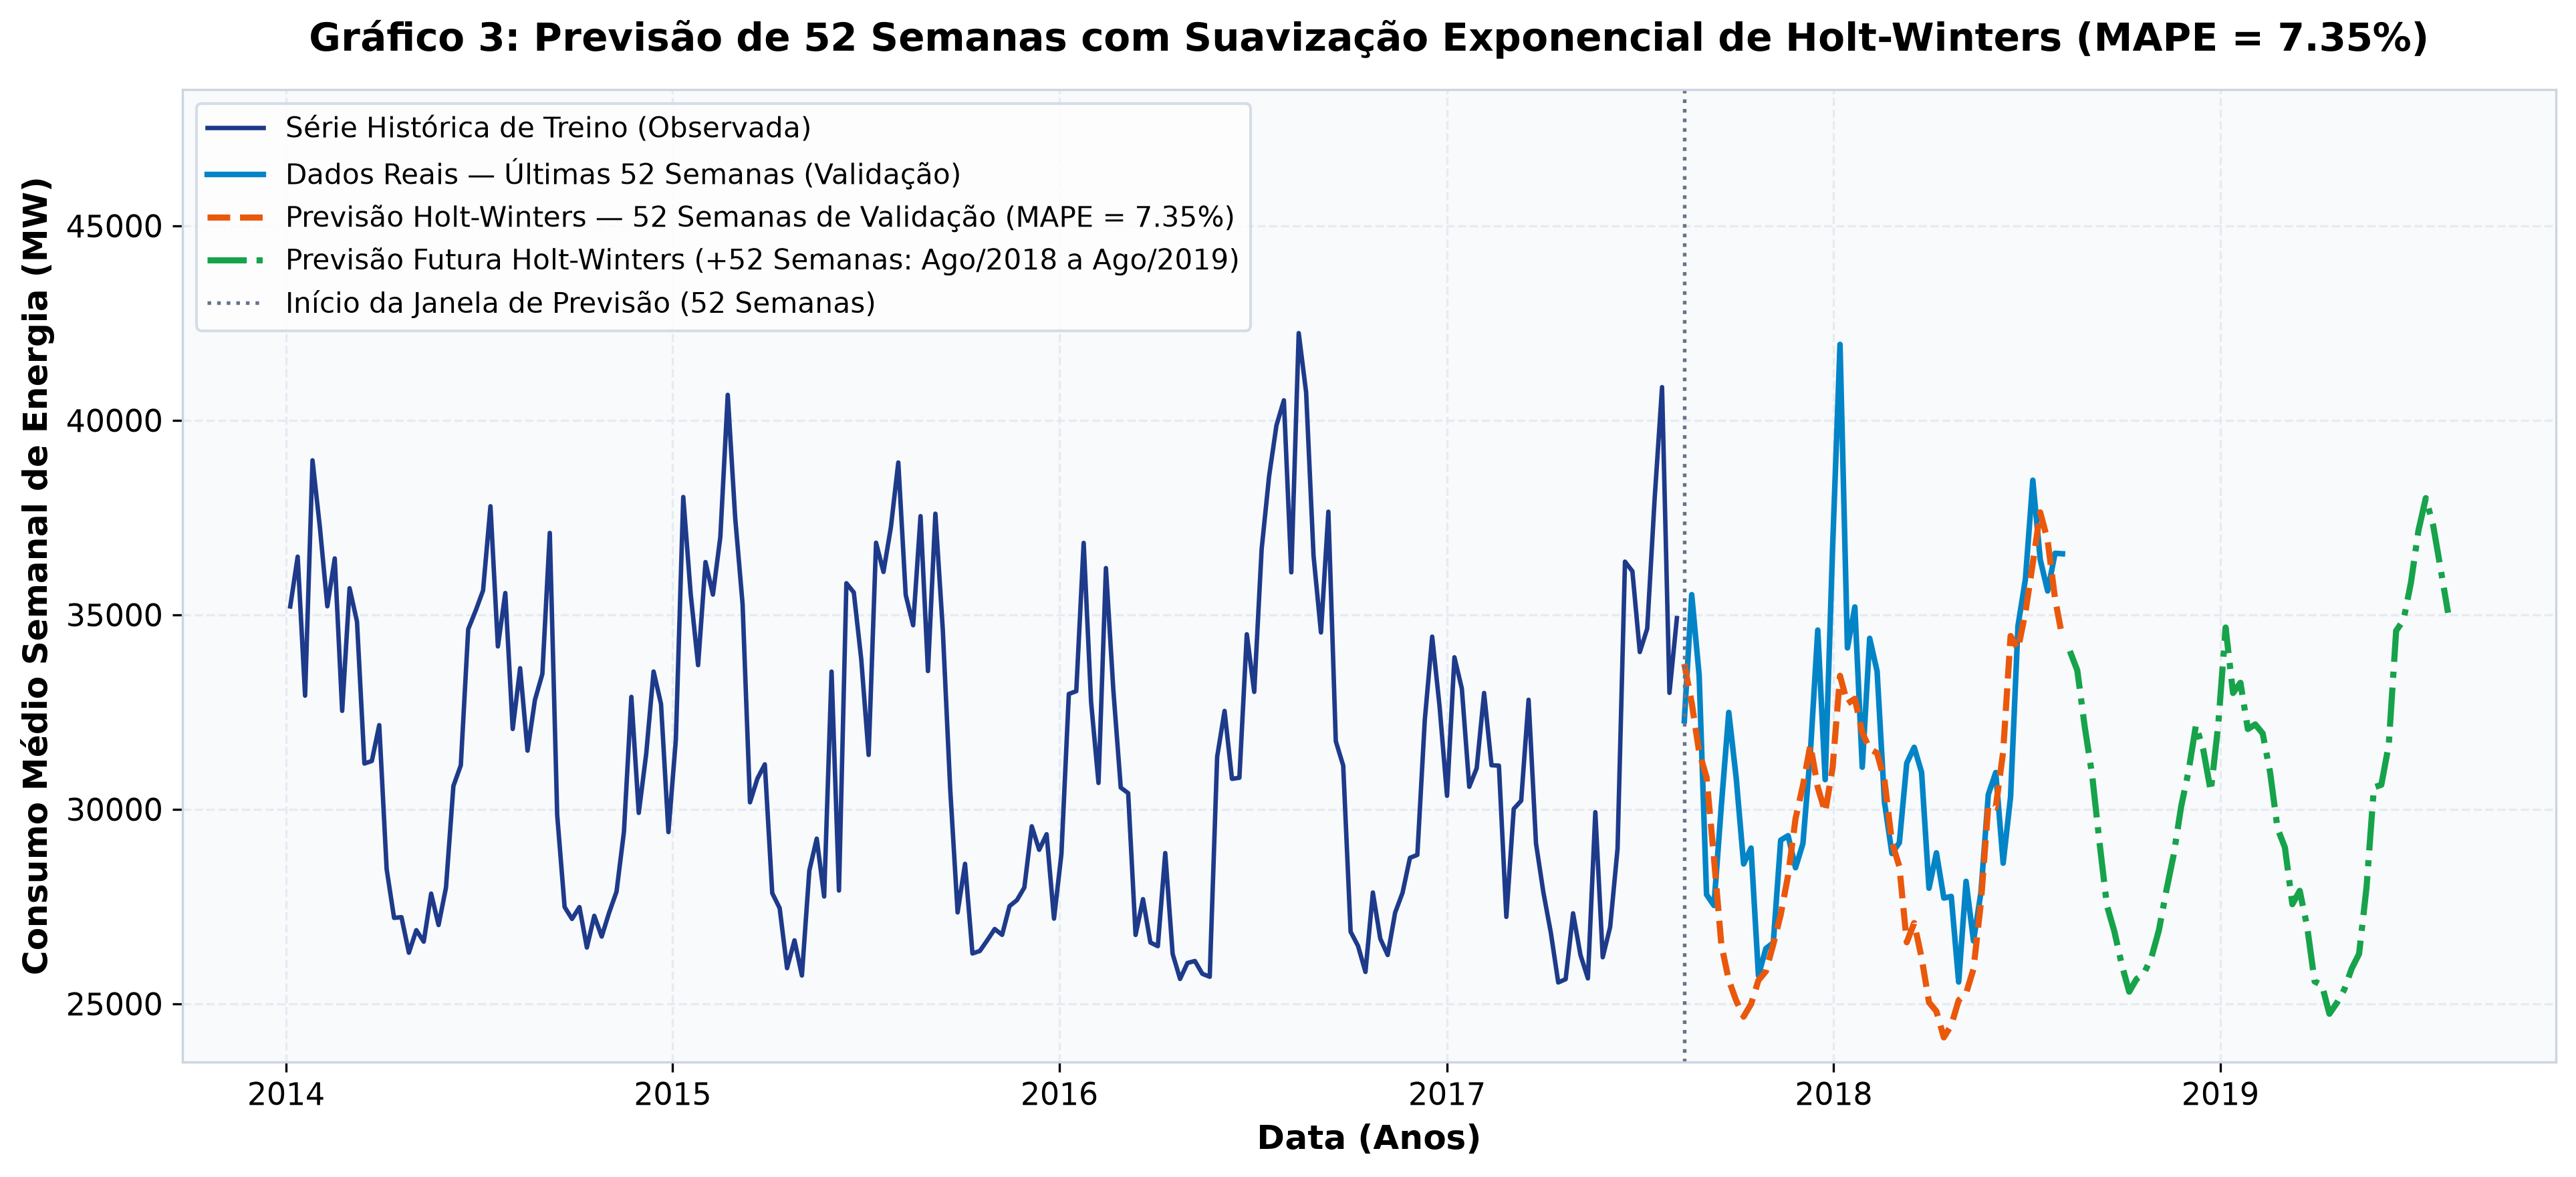

In [5]:
horizonte = 52

# Separação em Treino e Teste (últimas 52 semanas) para cálculo do MAPE
treino = serie_semanal.iloc[:-horizonte]
teste = serie_semanal.iloc[-horizonte:]

# Modelo Holt-Winters Aditivo (tendência aditiva + sazonalidade aditiva de 52 semanas)
modelo_validacao = ExponentialSmoothing(
    treino,
    trend="add",
    seasonal="add",
    seasonal_periods=52,
).fit()

previsao_teste = modelo_validacao.forecast(horizonte)

# Cálculo exclusivo do MAPE (%)
mape = np.mean(np.abs((teste - previsao_teste) / teste)) * 100
print(f"MAPE da previsão de 52 semanas (Holt-Winters Aditivo): {mape:.2f}%")

# Projeção futura para as próximas 52 semanas após o fim do dataset (2018–2019)
modelo_futuro = ExponentialSmoothing(
    serie_semanal,
    trend="add",
    seasonal="add",
    seasonal_periods=52,
).fit()
previsao_futura = modelo_futuro.forecast(horizonte)

# Visualização (recorte a partir de 2014 para total nitidez nos slides)
serie_recorte = treino.loc["2014-01-01":]

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(serie_recorte.index, serie_recorte.values, color="#1E3A8A", linewidth=1.6, label="Série Histórica de Treino (Observada)")
ax.plot(teste.index, teste.values, color="#0284C7", linewidth=2.0, label="Dados Reais — Últimas 52 Semanas (Validação)")
ax.plot(
    previsao_teste.index,
    previsao_teste.values,
    color="#EA580C",
    linestyle="--",
    linewidth=2.2,
    label=f"Previsão Holt-Winters — 52 Semanas de Validação (MAPE = {mape:.2f}%)",
)
ax.plot(
    previsao_futura.index,
    previsao_futura.values,
    color="#16A34A",
    linestyle="-.",
    linewidth=2.2,
    label="Previsão Futura Holt-Winters (+52 Semanas: Ago/2018 a Ago/2019)",
)
ax.axvline(teste.index[0], color="#64748B", linestyle=":", linewidth=1.3, label="Início da Janela de Previsão (52 Semanas)")

ax.set_title(f"Gráfico 3: Previsão de 52 Semanas com Suavização Exponencial de Holt-Winters (MAPE = {mape:.2f}%)", pad=14)
ax.set_xlabel("Data (Anos)")
ax.set_ylabel("Consumo Médio Semanal de Energia (MW)")
ax.set_ylim(23500, 48500)
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

## 5. Respostas Objetivas às Perguntas Fundamentais

1. **A série possui Tendência? Se sim, que tipo?**  
   **Sim.** A decomposição revela uma tendência de crescimento moderado entre 2002 e 2007 (atingindo ~33.600 MW médios), seguida por uma **tendência suave de queda e estabilização** entre 2008 e 2018 (patamar de ~31.000 a 32.000 MW), explicada pelo avanço de programas de eficiência energética (LED, equipamentos mais eficientes) e geração solar distribuída na costa leste dos EUA.

2. **A série possui Sazonalidade? Se sim, qual o período que ela acontece?**  
   **Sim.** Apresenta **forte sazonalidade anual aditiva com período de 52 semanas (1 ano)**. Dentro de cada ciclo de 52 semanas há dois picos bem demarcados: o **pico principal no verão** (julho/agosto, pelo uso intenso de ar-condicionado) e um **pico secundário no inverno** (janeiro/fevereiro, para aquecimento), intercalados por vales na primavera e no outono.

3. **A série apresenta um Ciclo? Se sim, por qual razão?**  
   **Sim.** Observam-se oscilações plurianuais não periódicas na curva de tendência decorrentes de **ciclos macroeconômicos** (como a retração industrial após a crise financeira de 2008–2009) e **variações climáticas plurianuais** (anos com invernos ou verões mais extremos).

4. **Método de Previsão Escolhido:**  
   **Suavização Exponencial de Holt-Winters Aditivo** (`trend='add'`, `seasonal='add'`, `seasonal_periods=52`), pois modela simultaneamente nível, tendência e sazonalidade de amplitude constante. O modelo alcançou **MAPE de 7,35%** na previsão de 52 semanas.

5. **Insights de Negócio:**  
   - **Despacho e Contratação Antecipada:** Antecipar os picos de verão (>38.000 MW semanais) e inverno evita compras emergenciais de energia a custo elevado e risco de sobrecarga.
   - **Programação de Manutenção Preventiva:** Os vales sazonais previsíveis de primavera (abril/maio) e outono (outubro/novembro), quando a demanda cai para ~25.000 MW, são as janelas ideais para desligamentos programados de turbinas e linhas de transmissão.